In [57]:
### imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score


In [ ]:
airline_file_path = 'PATH/TO/YOUR/AIRLINE_DATASET.csv'
booking_file_path = 'PATH/TO/YOUR/BOOKING_DATASET.csv'


In [3]:
airline_df = pd.read_csv(airline_file_path)
booking_df = pd.read_csv(booking_file_path)

In [4]:
booking_df.drop(columns=['booking_complete'], inplace=True)


In [5]:
airline_df.drop(columns=['Passanger_Name', 'Flying_Date', 'Review_title', 'Start_Location', 'End_Location', 'Layover_Route', 'Start_Latitude', 'Start_Longitude', 'Start_Address', 'End_Latitude', 'End_Longitude', 'End_Address'], inplace=True)

In [6]:
print(airline_df.isnull().sum())


Route             766
Rating              0
Verified            0
Review_content      0
Traveller_Type      0
Class               0
dtype: int64


In [7]:
print(booking_df.isnull().sum())


num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
dtype: int64


In [8]:
airline_df.dropna(subset=['Route'], inplace=True)


In [9]:
print(airline_df.isnull().sum())


Route             0
Rating            0
Verified          0
Review_content    0
Traveller_Type    0
Class             0
dtype: int64


In [10]:
duplicates_in_airline = airline_df.duplicated().sum()
duplicates_in_airline

2

In [11]:
duplicates_in_booking = booking_df.duplicated().sum()
duplicates_in_booking

727

In [12]:
airline_df.drop_duplicates(inplace=True)
duplicates_in_airline = airline_df.duplicated().sum()
duplicates_in_airline

0

In [13]:
booking_df.drop_duplicates(inplace=True)
duplicates_in_booking = booking_df.duplicated().sum()
duplicates_in_booking

0

In [14]:
!pip install vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 5.4 MB/s eta 0:00:00


In [15]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()


In [16]:
def get_sentiment_score(text):
    return analyzer.polarity_scores(text)['compound']


In [17]:
airline_df['sentiment_score'] = airline_df['Review_content'].apply(get_sentiment_score)
print("✅ Sentiment scores calculated and added to the 'sentiment_score' column.")

✅ Sentiment scores calculated and added to the 'sentiment_score' column.


In [19]:
def classify_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

In [20]:
airline_df['Sentiment_Analysis'] = airline_df['sentiment_score'].apply(classify_sentiment)

In [21]:
print("\nDistribution of sentiments:")
print(airline_df['Sentiment_Analysis'].value_counts())


Distribution of sentiments:
Sentiment_Analysis
Positive    1547
Negative    1225
Neutral       35
Name: count, dtype: int64


In [22]:
top_10_routes = booking_df['route'].value_counts()
top_10_routes = top_10_routes.head(10)
print(top_10_routes)


route
AKLKUL    2620
PENTPE     912
MELSGN     833
ICNSIN     792
DMKKIX     728
ICNSYD     683
DMKPER     677
DPSICN     658
DMKOOL     652
MELTPE     637
Name: count, dtype: int64


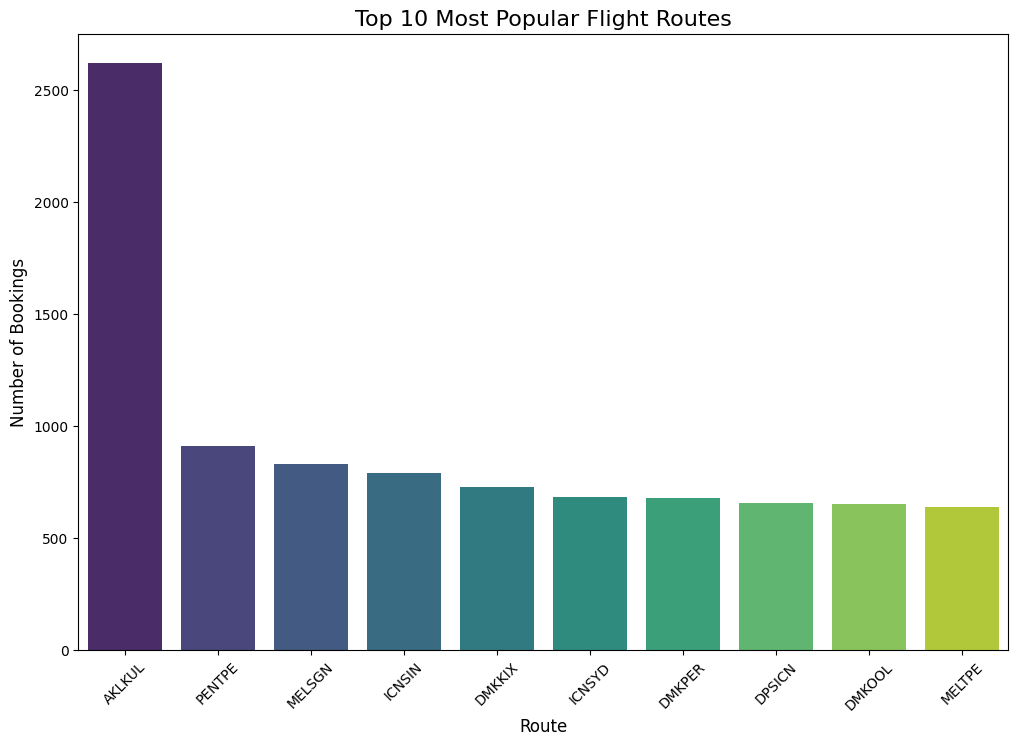

In [23]:
# 3. (Recommended) Visualize the results
plt.figure(figsize=(12, 8))
sns.barplot(x=top_10_routes.index, y=top_10_routes.values, palette='viridis')
plt.title('Top 10 Most Popular Flight Routes', fontsize=16)
plt.xlabel('Route', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.xticks(rotation=45)
plt.show()

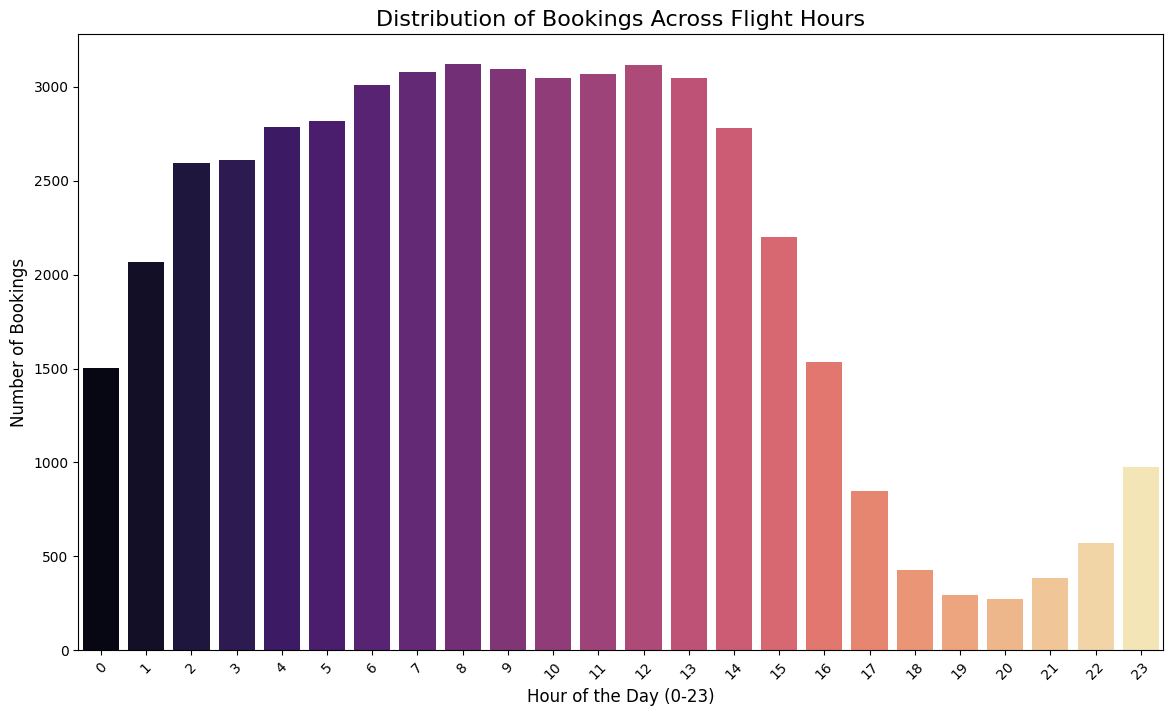


Number of bookings for each hour:
flight_hour
0     1501
1     2070
2     2596
3     2613
4     2785
5     2817
6     3011
7     3080
8     3124
9     3096
10    3050
11    3071
12    3114
13    3046
14    2783
15    2201
16    1536
17     848
18     430
19     294
20     275
21     386
22     573
23     975
Name: count, dtype: int64


In [24]:
# Set the figure size for better readability
plt.figure(figsize=(14, 8))

# Create a count plot to show the number of bookings for each hour
sns.countplot(x='flight_hour', data=booking_df, palette='magma')

# Add titles and labels for clarity
plt.title('Distribution of Bookings Across Flight Hours', fontsize=16)
plt.xlabel('Hour of the Day (0-23)', fontsize=12)
plt.ylabel('Number of Bookings', fontsize=12)
plt.xticks(rotation=45) # Rotate x-axis labels if they overlap

# Display the plot
plt.show()

# You can also get the exact numbers using value_counts()
flight_hour_counts = booking_df['flight_hour'].value_counts().sort_index()
print("\nNumber of bookings for each hour:")
print(flight_hour_counts)

In [25]:
rating_by_group = airline_df.groupby(['Traveller_Type', 'Class']).agg(
    average_rating=('Rating', 'mean'),
    review_count=('Rating', 'size')
).reset_index()

# Display the first few rows of the newly created summary DataFrame
print("Summary of Ratings by Group:")
rating_by_group.head()

Summary of Ratings by Group:


,Traveller_Type,Class,average_rating,review_count
0,Business,Business Class,3.498195,277
1,Business,Economy Class,3.457031,256
2,Business,First Class,4.270270,37
3,Business,Premium Economy,3.750000,52
4,Couple Leisure,Business Class,5.337349,332


In [26]:
sorted_ratings = rating_by_group.sort_values(by='average_rating', ascending=False)

# Display the full sorted table to see the complete ranking
print("--- Average Ratings for Each Combination (Sorted Highest to Lowest) ---")
print(sorted_ratings)

--- Average Ratings for Each Combination (Sorted Highest to Lowest) ---
    Traveller_Type            Class  average_rating  review_count
14    Solo Leisure      First Class        6.627907            43
6   Couple Leisure      First Class        5.983607            61
12    Solo Leisure   Business Class        5.780347           173
8   Family Leisure   Business Class        5.775000            80
15    Solo Leisure  Premium Economy        5.653061            98
4   Couple Leisure   Business Class        5.337349           332
18         Unknown      First Class        5.000000             1
13    Solo Leisure    Economy Class        4.631193           545
2         Business      First Class        4.270270            37
10  Family Leisure      First Class        4.230769            13
7   Couple Leisure  Premium Economy        4.221053            95
9   Family Leisure    Economy Class        4.069498           259
5   Couple Leisure    Economy Class        3.905908           457
3   

In [27]:

highest_rated = sorted_ratings.iloc[0]

# Get the last row for the lowest rated combination
lowest_rated = sorted_ratings.iloc[-1]

print(f"✅ Highest Rated Combination: '{highest_rated['Traveller_Type']}' in '{highest_rated['Class']}' with an average rating of {highest_rated['average_rating']:.2f} from {highest_rated['review_count']} reviews.")
print(f"✅ Lowest Rated Combination:  '{lowest_rated['Traveller_Type']}' in '{lowest_rated['Class']}' with an average rating of {lowest_rated['average_rating']:.2f} from {lowest_rated['review_count']} reviews.")

✅ Highest Rated Combination: 'Solo Leisure' in 'First Class' with an average rating of 6.63 from 43 reviews.
✅ Lowest Rated Combination:  'Various' in 'Economy Class' with an average rating of 1.00 from 1 reviews.


In [28]:
# Pivot the data to create a matrix suitable for a heatmap
heatmap_data = sorted_ratings.pivot(index='Traveller_Type', columns='Class', values='average_rating')

# Display the pivoted data to see the new structure
print("Pivoted Data for Heatmap:")
print(heatmap_data)

Pivoted Data for Heatmap:
Class           Business Class  Economy Class  First Class  Premium Economy  \
Traveller_Type                                                                
Business              3.498195       3.457031     4.270270         3.750000   
Couple Leisure        5.337349       3.905908     5.983607         4.221053   
Family Leisure        5.775000       4.069498     4.230769         3.600000   
Solo Leisure          5.780347       4.631193     6.627907         5.653061   
Unknown               1.000000            NaN     5.000000              NaN   
Various                    NaN       1.000000          NaN              NaN   

Class           Unknown  
Traveller_Type           
Business            NaN  
Couple Leisure      NaN  
Family Leisure      NaN  
Solo Leisure        1.0  
Unknown             NaN  
Various             NaN  


/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


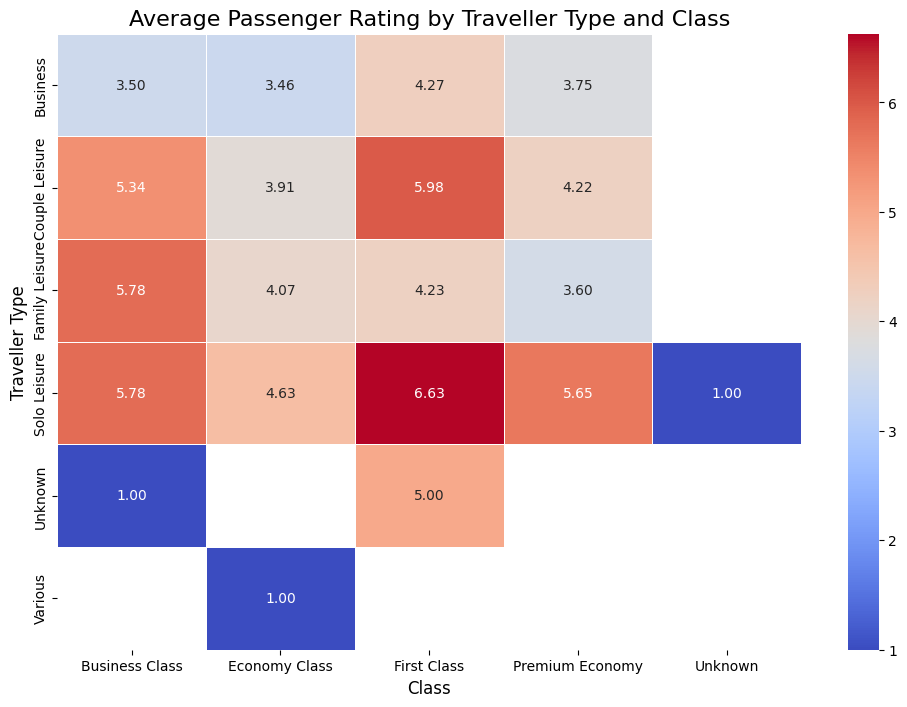

In [29]:
# Set the size of the figure
plt.figure(figsize=(12, 8))

# Create the heatmap
sns.heatmap(
    heatmap_data,
    annot=True,      # Show the average rating numbers in the cells
    fmt=".2f",       # Format the numbers to two decimal places
    cmap='coolwarm', # Use a color map that shows high vs. low values clearly
    linewidths=.5    # Add lines between cells for better separation
)

# Add titles and labels for clarity
plt.title('Average Passenger Rating by Traveller Type and Class', fontsize=16)
plt.xlabel('Class', fontsize=12)
plt.ylabel('Traveller Type', fontsize=12)

# Display the plot
plt.show()

In [30]:
airline_df['satisfaction'] = (airline_df['Rating'] >= 5).astype(int)
print(airline_df[['Rating', 'satisfaction']].head())

   Rating  satisfaction
0       1             0
1       1             0
2       2             0
3       4             0
4       7             1


In [31]:
airline_df.head()

,Route,Rating,Verified,Review_content,Traveller_Type,Class,sentiment_score,Sentiment_Analysis,satisfaction
0,New Orleans to London,1,Trip Verified,The airline lost my luggage and was absolutely...,Solo Leisure,Economy Class,-0.7990,Negative,0
1,London to Amman,1,Trip Verified,"We booked on the BA website, round trip flight...",Couple Leisure,Business Class,0.0219,Neutral,0
2,Heathrow to Bodrum,2,Trip Verified,"First time flying with BA business class, neve...",Solo Leisure,Business Class,-0.7096,Negative,0
3,Amman to London,4,Not Verified,You can buy sandwiches and crisps but don't ex...,Solo Leisure,Economy Class,-0.5849,Negative,0
4,London City to Ibiza,7,Trip Verified,This is a two-for-one review covering economy ...,Family Leisure,Business Class,0.9789,Positive,1


In [37]:
feature_columns = [
    'Traveller_Type',
    'Class',
    'Verified',
    'sentiment_score'
]

X = airline_df[feature_columns]
y = airline_df['satisfaction']


In [38]:
print(X.head())


   Traveller_Type           Class       Verified  sentiment_score
0    Solo Leisure   Economy Class  Trip Verified          -0.7990
1  Couple Leisure  Business Class  Trip Verified           0.0219
2    Solo Leisure  Business Class  Trip Verified          -0.7096
3    Solo Leisure   Economy Class   Not Verified          -0.5849
4  Family Leisure  Business Class  Trip Verified           0.9789


In [39]:
print(y.head())

0    0
1    0
2    0
3    0
4    1
Name: satisfaction, dtype: int64


In [41]:
X_processed = X.copy()


In [42]:
# Define the mapping for the 'Verified' column
verified_map = {'Trip Verified': 1, 'Not Verified': 0}

# Apply the mapping
X_processed['Verified'] = X_processed['Verified'].map(verified_map)

print("--- 'Verified' column after encoding ---")
print(X_processed['Verified'].value_counts())
print(X_processed.head())

--- 'Verified' column after encoding ---
Verified
0    1741
1    1066
Name: count, dtype: int64
   Traveller_Type           Class  Verified  sentiment_score
0    Solo Leisure   Economy Class         1          -0.7990
1  Couple Leisure  Business Class         1           0.0219
2    Solo Leisure  Business Class         1          -0.7096
3    Solo Leisure   Economy Class         0          -0.5849
4  Family Leisure  Business Class         1           0.9789


In [43]:
# Define the explicit order for the 'Class' column
# We include 'Unknown' with the lowest value in case it appears.
class_map = {
    'Economy Class': 0,
    'Premium Economy': 1,
    'Business Class': 2,
    'First Class': 3,
    'Unknown': 0 # Treat 'Unknown' class same as Economy
}

# Apply the mapping
X_processed['Class'] = X_processed['Class'].map(class_map)

print("\n--- 'Class' column after encoding ---")
print(X_processed['Class'].value_counts())
print(X_processed.head())


--- 'Class' column after encoding ---
Class
0    1519
2     863
1     270
3     155
Name: count, dtype: int64
   Traveller_Type  Class  Verified  sentiment_score
0    Solo Leisure      0         1          -0.7990
1  Couple Leisure      2         1           0.0219
2    Solo Leisure      2         1          -0.7096
3    Solo Leisure      0         0          -0.5849
4  Family Leisure      2         1           0.9789


In [44]:
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# 2. Fit and transform the 'Traveller_Type' column
# We need to reshape the column to be 2D for the encoder
traveller_type_encoded = ohe.fit_transform(X_processed[['Traveller_Type']])

In [45]:
# The feature names are retrieved from the encoder
encoded_df = pd.DataFrame(traveller_type_encoded, columns=ohe.get_feature_names_out(['Traveller_Type']))

In [46]:
# Reset index of both dataframes to ensure they align correctly before merging
X_processed.reset_index(drop=True, inplace=True)
encoded_df.reset_index(drop=True, inplace=True)

In [47]:
X_processed = pd.concat([X_processed, encoded_df], axis=1)


In [48]:
X_processed.drop('Traveller_Type', axis=1, inplace=True)


In [49]:
print("\n--- Final Processed DataFrame (X_processed) ---")
print(X_processed.head())


--- Final Processed DataFrame (X_processed) ---
   Class  Verified  sentiment_score  Traveller_Type_Business  \
0      0         1          -0.7990                      0.0   
1      2         1           0.0219                      0.0   
2      2         1          -0.7096                      0.0   
3      0         0          -0.5849                      0.0   
4      2         1           0.9789                      0.0   

   Traveller_Type_Couple Leisure  Traveller_Type_Family Leisure  \
0                            0.0                            0.0   
1                            1.0                            0.0   
2                            0.0                            0.0   
3                            0.0                            0.0   
4                            0.0                            1.0   

   Traveller_Type_Solo Leisure  Traveller_Type_Unknown  Traveller_Type_Various  
0                          1.0                     0.0                     0.0  
1

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, 
    y, 
    test_size=0.2, 
    random_state=42,
    stratify=y
)

In [52]:
print("Data splitting complete.")
print(f"Shape of X_train (features for training): {X_train.shape}")
print(f"Shape of y_train (target for training):   {y_train.shape}")
print(f"Shape of X_test (features for testing):   {X_test.shape}")
print(f"Shape of y_test (target for testing):     {y_test.shape}")

Data splitting complete.
Shape of X_train (features for training): (2245, 9)
Shape of y_train (target for training):   (2245,)
Shape of X_test (features for testing):   (562, 9)
Shape of y_test (target for testing):     (562,)


In [54]:
model_lr = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)


In [55]:
print("Training the Logistic Regression model...")
model_lr.fit(X_train, y_train)


Training the Logistic Regression model...


LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [58]:

# 1. Use the trained model to make predictions on the test set.
y_pred_lr = model_lr.predict(X_test)

# 2. Calculate the overall accuracy.
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"--- Logistic Regression Model Performance ---")
print(f"Overall Accuracy: {accuracy_lr:.4f}\n")

# 3. Generate a detailed Classification Report.
#    This report includes precision, recall, and F1-score for each class.
print("Classification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['Dissatisfied (0)', 'Satisfied (1)']))

--- Logistic Regression Model Performance ---
Overall Accuracy: 0.8060

Classification Report:
                  precision    recall  f1-score   support

Dissatisfied (0)       0.89      0.75      0.81       318
   Satisfied (1)       0.73      0.87      0.80       244

        accuracy                           0.81       562
       macro avg       0.81      0.81      0.81       562
    weighted avg       0.82      0.81      0.81       562



In [59]:
from sklearn.ensemble import RandomForestClassifier

# --- Initialize and Train the Random Forest Model ---

# 1. Initialize the model.
#    - n_estimators=100 means we will build 100 decision trees.
#    - random_state=42 for reproducibility.
#    - class_weight='balanced_subsample' is a good practice for Random Forest to handle class imbalance.
model_rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced_subsample', n_jobs=-1)

# 2. Train the model on the same training data.
print("Training the Random Forest model...")
model_rf.fit(X_train, y_train)

print("✅ Model training complete.")

Training the Random Forest model...
✅ Model training complete.


In [60]:
# Cell 9
from sklearn.metrics import classification_report, accuracy_score

# --- Make Predictions and Evaluate the Random Forest ---

# 1. Use the trained model to make predictions on the test set.
y_pred_rf = model_rf.predict(X_test)

# 2. Calculate the overall accuracy.
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"--- Random Forest Model Performance ---")
print(f"Overall Accuracy: {accuracy_rf:.4f}\n")

# 3. Generate a detailed Classification Report.
print("Classification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Dissatisfied (0)', 'Satisfied (1)']))

--- Random Forest Model Performance ---
Overall Accuracy: 0.7064

Classification Report:
                  precision    recall  f1-score   support

Dissatisfied (0)       0.74      0.74      0.74       318
   Satisfied (1)       0.66      0.67      0.66       244

        accuracy                           0.71       562
       macro avg       0.70      0.70      0.70       562
    weighted avg       0.71      0.71      0.71       562



In [61]:
!pip install shap


In [62]:
import shap

# --- Initialize the SHAP Explainer ---

# For linear models like Logistic Regression, we use the shap.LinearExplainer.
# It's highly optimized for this type of model.
# We pass it our trained model (model_lr) and the training data (X_train).
explainer = shap.LinearExplainer(model_lr, X_train)

# Calculate the SHAP values for the test set. 
# This tells us how each feature contributed to the prediction for each review in the test set.
shap_values = explainer.shap_values(X_test)

print("✅ SHAP explainer initialized and values calculated.")

✅ SHAP explainer initialized and values calculated.


--- Generating SHAP Summary Plot ---
This plot shows the most important features for the model.


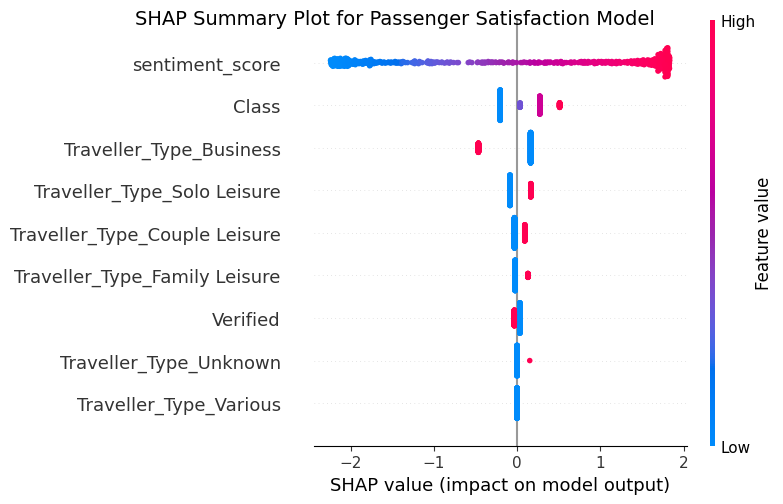

In [65]:
import shap
import matplotlib.pyplot as plt

# --- Create the SHAP Summary Plot ---

print("--- Generating SHAP Summary Plot ---")
print("This plot shows the most important features for the model.")

# Create the plot
shap.summary_plot(shap_values, X_test, show=False) # Use show=False to prevent auto-display

# Get a reference to the current figure and add the title
plt.gcf().suptitle("SHAP Summary Plot for Passenger Satisfaction Model", size=14)
plt.show() # Now display the completed plot

In [64]:
# Cell 12
import lime
import lime.lime_tabular

# --- Initialize the LIME Explainer ---

# LIME needs to understand the structure of your training data.
# We provide:
# - X_train.values: The numpy array of your training data.
# - feature_names: The column names of your processed features.
# - class_names: The names for your target variable (0 and 1).
# - mode='classification': To tell LIME this is a classification problem.

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=['Dissatisfied', 'Satisfied'],
    mode='classification'
)

print("✅ LIME explainer initialized successfully.")

✅ LIME explainer initialized successfully.


In [69]:
# Cell 13
import numpy as np

# Find the index of a passenger that was ACTUALLY Dissatisfied (0) and PREDICTED Dissatisfied (0)
correctly_dissatisfied_idx = np.where((y_test == 0) & (y_pred_lr == 0))[0][0]

# Find the index of a passenger that was ACTUALLY Satisfied (1) and PREDICTED Satisfied (1)
correctly_satisfied_idx = np.where((y_test == 1) & (y_pred_lr == 1))[0][0]

print(f"We will explain the prediction for test set passenger at index: {correctly_dissatisfied_idx} (Dissatisfied)")
print(f"We will also explain the prediction for test set passenger at index: {correctly_satisfied_idx} (Satisfied)")

We will explain the prediction for test set passenger at index: 1 (Dissatisfied)
We will also explain the prediction for test set passenger at index: 4 (Satisfied)


In [70]:
# Cell 13a
import pandas as pd

# This function takes a numpy array from LIME, converts it back to a DataFrame 
# with the correct column names, and then gets the prediction from our model.
def predict_fn_wrapper(x):
    x_df = pd.DataFrame(x, columns=X_train.columns)
    return model_lr.predict_proba(x_df)

print("✅ LIME helper function created.")

✅ LIME helper function created.


In [71]:
# Cell 14 (Corrected)
# --- Generate LIME explanation for the DISSATISFIED passenger ---

instance_dissatisfied = X_test.iloc[correctly_dissatisfied_idx].values

# Use the NEW wrapper function here
explanation_dissatisfied = lime_explainer.explain_instance(
    instance_dissatisfied,
    predict_fn_wrapper, # <--- THE FIX
    num_features=5 
)

print(f"\n--- LIME Explanation for Dissatisfied Passenger (Index: {correctly_dissatisfied_idx}) ---")
explanation_dissatisfied.show_in_notebook(show_table=True)


--- LIME Explanation for Dissatisfied Passenger (Index: 1) ---


In [72]:
# Cell 15 (Corrected)
# --- Generate LIME explanation for the SATISFIED passenger ---

instance_satisfied = X_test.iloc[correctly_satisfied_idx].values

# Use the NEW wrapper function here
explanation_satisfied = lime_explainer.explain_instance(
    instance_satisfied,
    predict_fn_wrapper, # <--- THE FIX
    num_features=5
)

print(f"\n--- LIME Explanation for Satisfied Passenger (Index: {correctly_satisfied_idx}) ---")
explanation_satisfied.show_in_notebook(show_table=True)


--- LIME Explanation for Satisfied Passenger (Index: 4) ---
